# 04 · Augmentation study

**Owner:** Sukhraj · **Phase 4** of the StayScope pipeline

**Research question 2:** when a platform lacks engagement data, can behavioural features borrowed from *similar*
customers in another dataset recover the missing signal?

Set-up:
* **Target:** dataset A without its engagement columns (`watch_hours`, `last_login_days`, `avg_watch_time_per_day`),
  called **`A_hard`**. Without them, a model only reaches ROC-AUC ≈ 0.62 (vs ≈ 0.999 with them).
* **Donor:** dataset S (243,787 customers) with its behavioural columns.
* **Matching:** cosine KNN on the five harmonized shared columns from notebook 03 (one-hot, standardized),
  K = 5, keep neighbours with similarity ≥ 0.6, drop A customers with none.
* **Transfer:** similarity-weighted mean of each transfer feature over the valid neighbours.
* **Control:** `A_hard_random`, the same customers given features from *random* S customers. If the matched
  version cannot beat random, matching adds nothing.

| Experiment | Rows | Features |
|---|---|---|
| `A_hard` | matched A rows | A without the engagement columns (baseline) |
| `A_hard_augmented` | matched A rows | A_hard + 5 features transferred from S neighbours |
| `A_hard_random` | matched A rows | A_hard + 5 features from random S customers (control) |

**Plan:** 1) the **pre-check** (can the shared columns predict the features we transfer at all?), 2) matching,
3) transfer, 4) a quick preview of the result, 5) write the datasets for notebook 05.

The churn label is never part of the matching vector, and S's churn label is never transferred.
Logic: `src/churn/matching.py`.

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from churn import config, data, evaluate as ev, features as F, matching as MT, models as M
from churn.plotting import CHURN, MEDIUM, MODEL_COLORS, NEUTRAL, RETAINED, savefig, set_style

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
set_style()
config.ensure_dirs()
TARGET, ID = config.TARGET, config.ID_COL
EXP_COLORS = {"A_full": NEUTRAL, "A_hard": "#7C9CF5", "A_hard_augmented": RETAINED, "A_hard_random": "#A1A1AA"}

a_h, s_h = F.harmonize(data.load_clean_a(), data.load_clean_s())
print(f"A: {a_h.shape}, S: {s_h.shape}")
print("matching on:", F.COMMON_FEATURES)
print("transferring:", F.TRANSFER_FEATURES)
print(f"K = {config.K}, similarity threshold = {config.SIM_THRESHOLD}")

A: (5000, 17), S: (243787, 25)
matching on: ['plan_h', 'device_h', 'genre_h', 'payment_h', 'gender_h']
transferring: ['account_age', 'avg_viewing_duration', 'content_downloads_per_month', 'viewing_hours_per_week', 'support_tickets_per_month']
K = 5, similarity threshold = 0.6


## 2. Pre-check: can the shared columns predict S's behaviour?

Similarity-based transfer only works if customers who look alike on the shared columns also *behave* alike.
We test that directly inside S: for each behavioural column, a gradient-boosting regressor predicts it from the five
shared columns, scored by 5-fold cross-validated R². R² = 0 means "no better than predicting the average".

In [2]:
check = MT.transferability_check(s_h)
check.to_csv(config.RESULTS_DIR / "transferability.csv", index=False)
check.assign(transferred=check["feature"].isin(F.TRANSFER_FEATURES))

,feature,r2_mean,r2_std,transferred
0,account_age,-0.000,0.000,True
1,viewing_hours_per_week,-0.000,0.000,True
2,avg_viewing_duration,-0.000,0.000,True
3,content_downloads_per_month,-0.000,0.000,True
4,user_rating,-0.000,0.000,False
5,support_tickets_per_month,-0.000,0.000,True
6,watchlist_size,-0.000,0.000,False


max R²: -0.0001


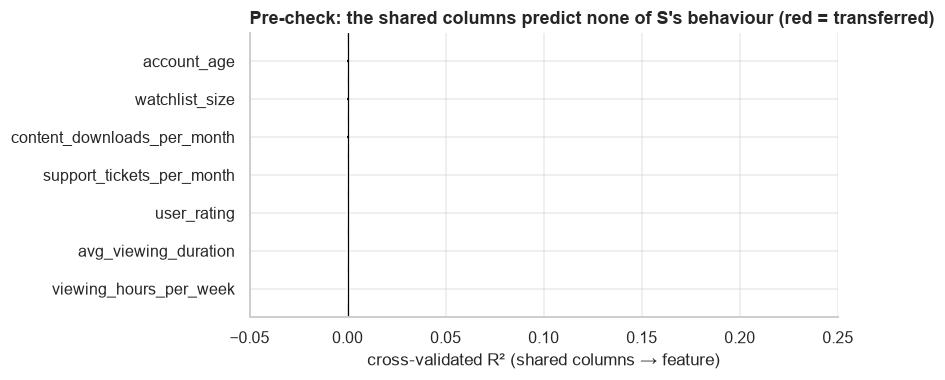

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
d = check.sort_values("r2_mean")
ax.barh(d["feature"], d["r2_mean"], xerr=d["r2_std"],
        color=[CHURN if f in F.TRANSFER_FEATURES else NEUTRAL for f in d["feature"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.05, 0.25)
ax.set_xlabel("cross-validated R² (shared columns → feature)")
ax.set_title("Pre-check: the shared columns predict none of S's behaviour (red = transferred)")
fig.tight_layout()
savefig(fig, "04_precheck_r2")
print(f"max R²: {check['r2_mean'].max():.4f}")

**Every R² is 0.000** (slightly negative, i.e. no better than the mean). Knowing a customer's plan, device, genre,
payment group and gender says nothing about their tenure, viewing or support behaviour in S. So the "similar"
customers KNN finds will behave like **random** S customers, and the transferred values are expected to be noise.
We run the matching anyway, because the study should show this with the full method, not just predict it.

## 3. Matching

Each A customer is encoded on the five harmonized columns (one-hot, standardized with S's statistics) and gets its
5 most cosine-similar S customers. S is shuffled with a fixed seed first, so when many S customers are tied
(identical profiles), the 5 are chosen at random rather than by file order.

In [4]:
X_a, X_s, enc_cols = MT.encode_common(a_h, s_h)
print(f"matching vector: {len(enc_cols)} columns")
print(enc_cols)
n_profiles_s = s_h[F.COMMON_FEATURES].drop_duplicates().shape[0]
n_profiles_a = a_h[F.COMMON_FEATURES].drop_duplicates().shape[0]
print(f"distinct shared-column profiles: S {n_profiles_s}, A {n_profiles_a}")

matching vector: 18 columns
['plan_h_Basic', 'plan_h_Premium', 'plan_h_Standard', 'device_h_Computer', 'device_h_Mobile', 'device_h_TV', 'device_h_Tablet', 'genre_h_Action', 'genre_h_Comedy', 'genre_h_Drama', 'genre_h_Other', 'genre_h_Sci-Fi', 'payment_h_card', 'payment_h_digital', 'payment_h_manual', 'gender_h_Female', 'gender_h_Male', 'gender_h_Other']
distinct shared-column profiles: S 360, A 534


In [5]:
out = MT.build_experiments(a_h, s_h)
report = out["match_report"]
report.to_csv(config.RESULTS_DIR / "match_report.csv", index=False)
summary = pd.Series({
    "A customers": len(report),
    "kept (≥1 valid neighbour)": int(report["kept"].sum()),
    "dropped": int((~report["kept"]).sum()),
    "mean valid neighbours": report["n_valid_neighbours"].mean(),
    "exact profile match (sim = 1)": f"{(report['max_sim'] > 0.9999).mean():.1%}",
    "mean similarity": report["mean_sim"].mean(),
    "min similarity": report["max_sim"].min(),
})
summary.to_frame("value")

,value
A customers,5000
kept (≥1 valid neighbour),5000
dropped,0
mean valid neighbours,5.000
exact profile match (sim = 1),67.3%
mean similarity,0.954
min similarity,0.845


,max_sim,mean_sim
gender_h,,
Female,1.000,1.000
Male,1.000,1.000
Other,0.859,0.859


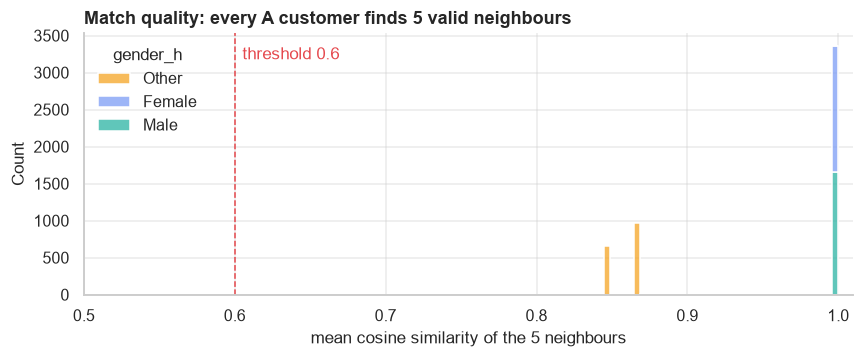

In [6]:
d = report.merge(a_h[[ID, "gender_h"]], on=ID)
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(d, x="mean_sim", hue="gender_h", bins=40, multiple="stack", ax=ax,
             palette={"Female": "#7C9CF5", "Male": RETAINED, "Other": MEDIUM})
ax.axvline(config.SIM_THRESHOLD, color=CHURN, ls="--", lw=1)
ax.text(config.SIM_THRESHOLD + 0.005, ax.get_ylim()[1] * 0.9, "threshold 0.6", color=CHURN)
ax.set_xlim(0.5, 1.01)
ax.set_xlabel("mean cosine similarity of the 5 neighbours")
ax.set_title("Match quality: every A customer finds 5 valid neighbours")
fig.tight_layout()
savefig(fig, "04_similarity_distribution")
d.groupby("gender_h")[["max_sim", "mean_sim"]].mean()

**Every A customer is kept, with 5 valid neighbours.** The shared columns form only about 360 distinct profiles in S,
each held by hundreds of S customers, so most A customers find **exact** profile matches (similarity 1.0). A's
gender *Other* customers (a third of A) have no exact counterpart in S; they still reach similarity ≈ 0.85–0.87,
comfortably above 0.6, because they match on the other four columns.

High similarity is therefore easy to get here, which is exactly why it is not informative: an "exact match" is just
one of hundreds of S customers with the same plan, device, genre, payment group and gender.

One example (the app's Augmentation page shows the same table):

In [7]:
example_id = a_h[ID].iloc[0]
display(a_h.loc[a_h[ID] == example_id, [ID, *F.COMMON_FEATURES, TARGET]])
MT.neighbours_for(example_id, a_h, s_h)

,customer_id,plan_h,device_h,genre_h,payment_h,gender_h,churned
0,a9b75100-82a8-427a-a208-72f24052884a,Basic,TV,Action,manual,Other,1


,rank,customer_id,similarity,valid,plan_h,device_h,genre_h,payment_h,gender_h,account_age,avg_viewing_duration,content_downloads_per_month,viewing_hours_per_week,support_tickets_per_month
0,1,XJPAZHSNIJ,0.868,True,Basic,TV,Action,manual,Male,18,91.421,12,30.039,2
1,2,TFILEJH6QT,0.868,True,Basic,TV,Action,manual,Male,56,46.246,38,32.919,5
2,3,ZAPMKKJHLQ,0.868,True,Basic,TV,Action,manual,Male,114,105.316,42,31.796,7
3,4,0K4T49MH30,0.868,True,Basic,TV,Action,manual,Male,89,112.739,46,11.195,7
4,5,0AKLHP8W9J,0.868,True,Basic,TV,Action,manual,Male,114,146.676,6,7.958,7


## 4. Transfer

For every kept A customer, each transfer feature is the similarity-weighted mean of its valid neighbours. The random
control gives each customer the same number of donors, drawn at random from S and weighted equally.

In [8]:
aug, rnd, hard = out["A_hard_augmented"], out["A_hard_random"], out["A_hard"]
assert len(aug) == len(rnd) == len(hard) and (aug[ID] == hard[ID]).all() and (rnd[ID] == hard[ID]).all()
print({k: v.shape for k, v in [("A_hard", hard), ("A_hard_augmented", aug), ("A_hard_random", rnd)]})
aug.head()

{'A_hard': (5000, 10), 'A_hard_augmented': (5000, 15), 'A_hard_random': (5000, 15)}


,customer_id,age,number_of_profiles,gender,subscription_type,region,device,payment_method,favorite_genre,account_age,avg_viewing_duration,content_downloads_per_month,viewing_hours_per_week,support_tickets_per_month,churned
0,a9b75100-82a8-427a-a208-72f24052884a,51,1,Other,Basic,Africa,TV,Gift Card,Action,78.200,100.480,28.800,22.781,5.600,1
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,5,Other,Standard,Europe,Mobile,Gift Card,Sci-Fi,60.400,69.874,28.200,17.688,2.800,1
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,2,Female,Standard,Asia,TV,Crypto,Drama,30.000,108.744,15.400,20.107,3.400,0
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,2,Other,Premium,Oceania,TV,Crypto,Horror,58.800,56.585,23.000,14.266,4.400,1
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,2,Other,Standard,Africa,Mobile,Crypto,Action,65.600,101.606,23.000,24.358,3.200,1


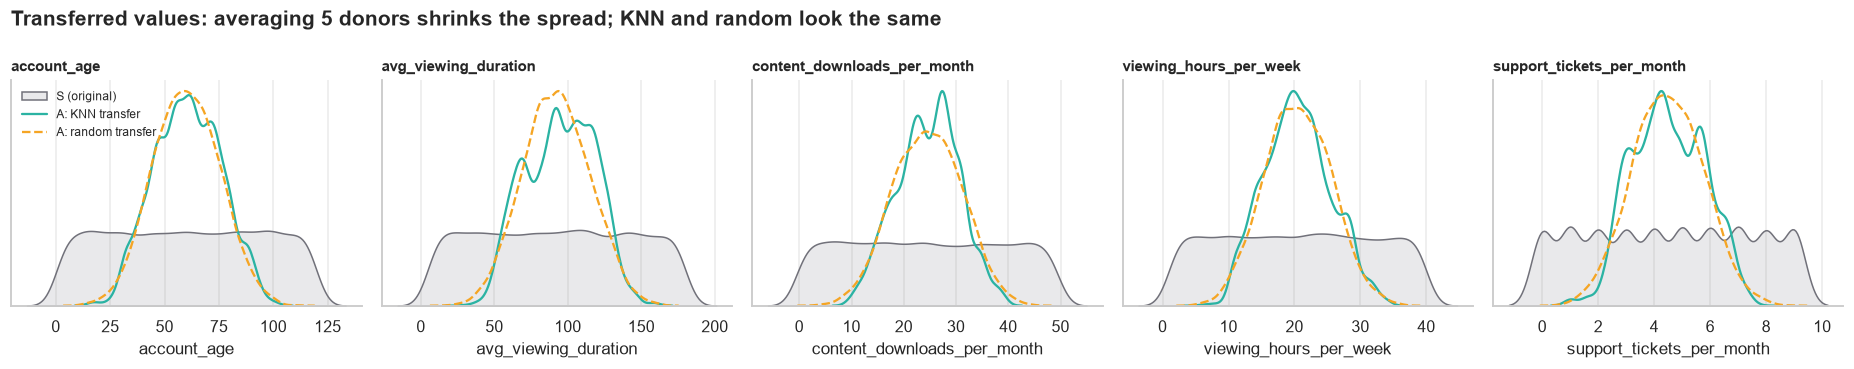

In [9]:
fig, axes = plt.subplots(1, len(F.TRANSFER_FEATURES), figsize=(17, 3.4))
s_sample = s_h.sample(20000, random_state=config.RANDOM_STATE)
for ax, f in zip(axes, F.TRANSFER_FEATURES):
    sns.kdeplot(s_sample[f], ax=ax, color=NEUTRAL, label="S (original)", fill=True, alpha=0.15)
    sns.kdeplot(aug[f], ax=ax, color=RETAINED, label="A: KNN transfer")
    sns.kdeplot(rnd[f], ax=ax, color=MEDIUM, ls="--", label="A: random transfer")
    ax.set_title(f, fontsize=10)
    ax.set_ylabel("")
    ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Transferred values: averaging 5 donors shrinks the spread; KNN and random look the same",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "04_transferred_distributions")

The KNN and random versions have the **same distribution**: matching does not pick out a different kind of S
customer. Both are narrower than S itself, because each value is an average of 5 donors.

The decisive question is whether the transferred values relate to **A's** churn:

In [10]:
rows = []
for name, df in [("A_hard_augmented", aug), ("A_hard_random", rnd)]:
    for f in F.TRANSFER_FEATURES:
        rows.append({"experiment": name, "feature": f, "spearman_rho_with_A_churn": df[f].corr(df[TARGET], method="spearman")})
rho = pd.DataFrame(rows).pivot(index="feature", columns="experiment", values="spearman_rho_with_A_churn")
rho["same feature in S"] = [s_h[f].corr(s_h[TARGET], method="spearman") for f in rho.index]
rho

experiment,A_hard_augmented,A_hard_random,same feature in S
feature,,,
account_age,0.014,0.005,-0.198
avg_viewing_duration,-0.015,-0.020,-0.147
content_downloads_per_month,-0.010,0.017,-0.130
support_tickets_per_month,-0.005,0.002,0.084
viewing_hours_per_week,0.014,0.014,-0.129


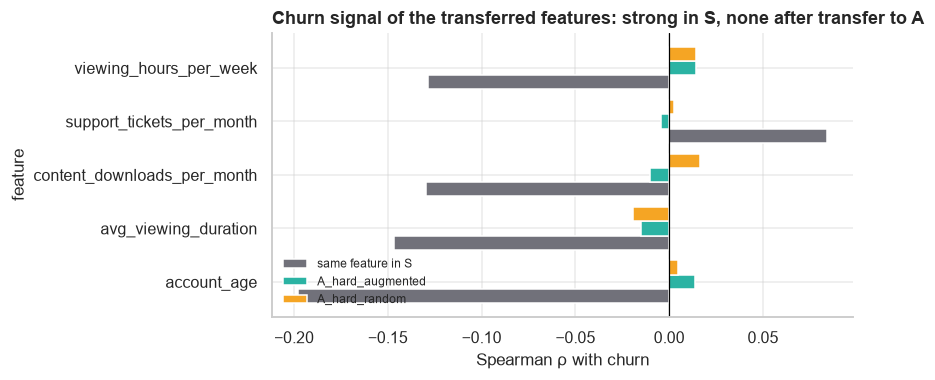

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
rho[["same feature in S", "A_hard_augmented", "A_hard_random"]].plot.barh(
    ax=ax, color=[NEUTRAL, RETAINED, MEDIUM], width=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman ρ with churn")
ax.set_title("Churn signal of the transferred features: strong in S, none after transfer to A")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
savefig(fig, "04_transferred_vs_churn")

In S these features are the strongest churn drivers (ρ up to −0.20). After transfer to A their association with A's
churn is ≈ 0, for KNN and random alike. The signal does not survive the trip, because the matching carries no
information about who the customer really is.

## 5. Preview: does augmentation help a model?

The **official** comparison (4 tuned models, 5 seeds, test set, class weighting) is run by notebook 05 on the files
written below. Here is a quick preview on the **validation** split only: Logistic Regression and XGBoost with
their default settings, 5 seeds. The test split is not touched.

In [12]:
spec_aug = M.SPEC_A_HARD.add(numeric=F.TRANSFER_FEATURES)
a_full_kept = data.load_clean_a().merge(hard[[ID]], on=ID)  # the A_full ceiling on the same customers
setups = {
    "A_full": (a_full_kept, M.SPEC_A),
    "A_hard": (hard, M.SPEC_A_HARD),
    "A_hard_augmented": (aug, spec_aug),
    "A_hard_random": (rnd, spec_aug),
}
rows = []
for exp, (df, spec) in setups.items():
    for seed in config.SEEDS:
        train, val, _ = M.stratified_split(df, seed)
        for model in ["logistic_regression", "xgboost"]:
            pipe = M.make_pipeline(model, spec, train[TARGET], seed=seed).fit(train[spec.columns], train[TARGET])
            p = pipe.predict_proba(val[spec.columns])[:, 1]
            rows.append({"experiment": exp, "model": model, "seed": seed, **ev.metrics_from_proba(val[TARGET], p)})
preview = pd.DataFrame(rows)
table = preview.groupby(["experiment", "model"])[["roc_auc", "pr_auc", "f1"]].agg(["mean", "std"])
table.loc[list(setups)]

roc_auc       pr_auc          f1      
                                        mean   std   mean   std  mean   std
experiment       model                                                     
A_full           logistic_regression   0.963 0.003  0.965 0.003 0.890 0.008
                 xgboost               0.999 0.000  0.999 0.000 0.985 0.006
A_hard           logistic_regression   0.629 0.022  0.607 0.021 0.570 0.013
                 xgboost               0.605 0.010  0.570 0.016 0.595 0.009
A_hard_augmented logistic_regression   0.631 0.023  0.608 0.021 0.573 0.014
                 xgboost               0.622 0.008  0.596 0.016 0.600 0.012
A_hard_random    logistic_regression   0.629 0.022  0.607 0.022 0.574 0.018
                 xgboost               0.623 0.026  0.588 0.026 0.603 0.024

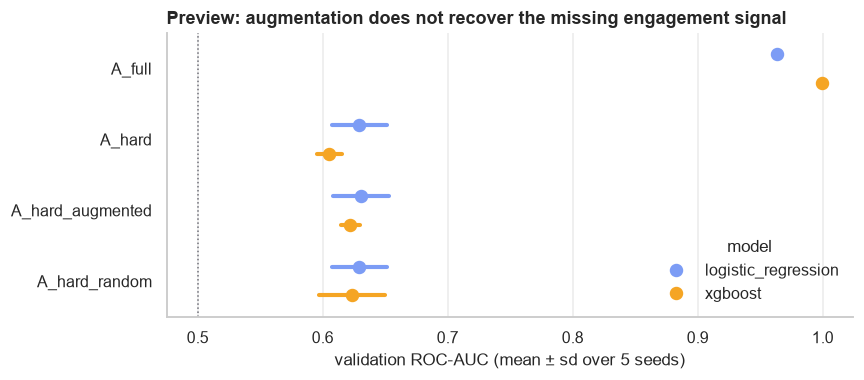

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.pointplot(preview, x="roc_auc", y="experiment", hue="model", order=list(setups), dodge=0.4,
              palette={m: MODEL_COLORS[m] for m in ["logistic_regression", "xgboost"]},
              errorbar="sd", linestyle="none", markers="o", ax=ax)
ax.axvline(0.5, color=NEUTRAL, ls=":", lw=1)
ax.set_xlabel("validation ROC-AUC (mean ± sd over 5 seeds)")
ax.set_ylabel("")
ax.set_title("Preview: augmentation does not recover the missing engagement signal")
fig.tight_layout()
savefig(fig, "04_preview_auc")

In [14]:
m = preview.groupby(["experiment", "model"])["roc_auc"].mean().unstack()
gap = pd.DataFrame({
    "augmented − A_hard": m.loc["A_hard_augmented"] - m.loc["A_hard"],
    "augmented − random": m.loc["A_hard_augmented"] - m.loc["A_hard_random"],
    "share of the gap to A_full recovered": (m.loc["A_hard_augmented"] - m.loc["A_hard"]) / (m.loc["A_full"] - m.loc["A_hard"]),
})
gap

,augmented − A_hard,augmented − random,share of the gap to A_full recovered
model,,,
logistic_regression,0.001,0.001,0.004
xgboost,0.017,-0.001,0.043


## 6. Write the experiment datasets

Written to `data/processed/` (gitignored, regenerate with `python -m churn.matching`). Notebook 05, section 10,
picks them up automatically.

In [15]:
for name in ("A_hard", "A_hard_augmented", "A_hard_random"):
    out[name].to_csv(config.experiment_path(name), index=False)
    print(f"{config.experiment_path(name).relative_to(config.ROOT)}  {out[name].shape}")
for f in ("transferability.csv", "match_report.csv"):
    print((config.RESULTS_DIR / f).relative_to(config.ROOT))

data\processed\A_hard.csv  (5000, 10)
data\processed\A_hard_augmented.csv  (5000, 15)
data\processed\A_hard_random.csv  (5000, 15)
reports\results\transferability.csv
reports\results\match_report.csv


## 7. Key findings

1. **The pre-check fails.** Inside S, the five shared columns predict none of the seven behavioural columns
   (cross-validated R² = 0.000 for all). Similar-looking customers do not behave alike, so the method has nothing to
   transfer.
2. **Matching looks excellent on paper.** All 5,000 A customers are kept with 5 valid neighbours, 67% find exact
   profile matches (similarity 1.0), and the rest (A's gender *Other*) reach ≈ 0.86. But the shared columns form only
   360 profiles in S, so an "exact match" is one of hundreds of interchangeable S customers. **High similarity is not
   evidence of a useful match.**
3. **The signal does not survive the transfer.** In S the transferred features are the strongest churn drivers
   (ρ up to −0.20); in A their association with churn is ≈ 0 (|ρ| ≤ 0.02), exactly like the random control.
4. **Preview result (validation, 5 seeds): no real gain.** Logistic Regression: A_hard 0.629 → augmented 0.631 →
   random 0.629 ROC-AUC. XGBoost gains about +0.02 from *any* five extra numeric columns, but the random control gains
   the same (augmented − random ≈ 0.00), so the gain comes from the extra columns, not from the matching. Augmentation
   recovers **0–4%** of the gap to the A_full ceiling (0.96–0.999).
5. **Answer to research question 2 (for these datasets):** borrowing behaviour from similar customers in another
   dataset **does not** recover the missing engagement signal, because the columns the two datasets share do not
   predict behaviour. The pre-check (step 1) is a cheap test that predicts this before any matching is done. This is
   the lesson for practice: **check that the shared columns predict the target features before augmenting.**
6. The official numbers (4 tuned models, test set) come from notebook 05, section 10, using the files written above.